In [2]:
import pandas as pd
import matplotlib.pyplot as plt

def plotTrainTrans(history_path):
    df = pd.read_csv(history_path).sort_values("epoch")

    panels = [
        ("Generator loss", ("gen_ab", "gen_ba"), ("A → B", "B → A")),
        ("Cycle loss", ("cycle_a", "cycle_b"), ("Domain A", "Domain B")),
        ("Discriminator loss", ("disc_a", "disc_b"), ("Domain A", "Domain B")),
        ("Identity loss", ("idt_a", "idt_b"), ("Domain A", "Domain B")),
        ("Gradient penalty", ("gp_a", "gp_b"), ("Domain A", "Domain B")),
    ]
    colors = ("#2563eb", "#f97316")

    fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
    fig.suptitle("UVCGAN2 training history", fontsize=17, fontweight="bold")

    for ax, (title, columns, labels) in zip(axes.flat, panels):
        for column, label, color in zip(columns, labels, colors):
            final_value = df[column].iloc[-1]
            ax.plot(
                df["epoch"], df[column],
                color=color, marker="o", markersize=4, linewidth=2,
                label=f"{label}  ({final_value:.4f})",
            )
        ax.set_title(title, loc="left", fontweight="bold")
        ax.set_ylabel("Loss")
        ax.grid(True, color="#d1d5db", linewidth=0.8, alpha=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, fontsize=9)
        ax.set_xticks(df["epoch"])
        ax.margins(x=0.04, y=0.18)

    axes[2, 1].set_visible(False)
    for ax in axes[2, :]:
        ax.set_xlabel("Epoch")

    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

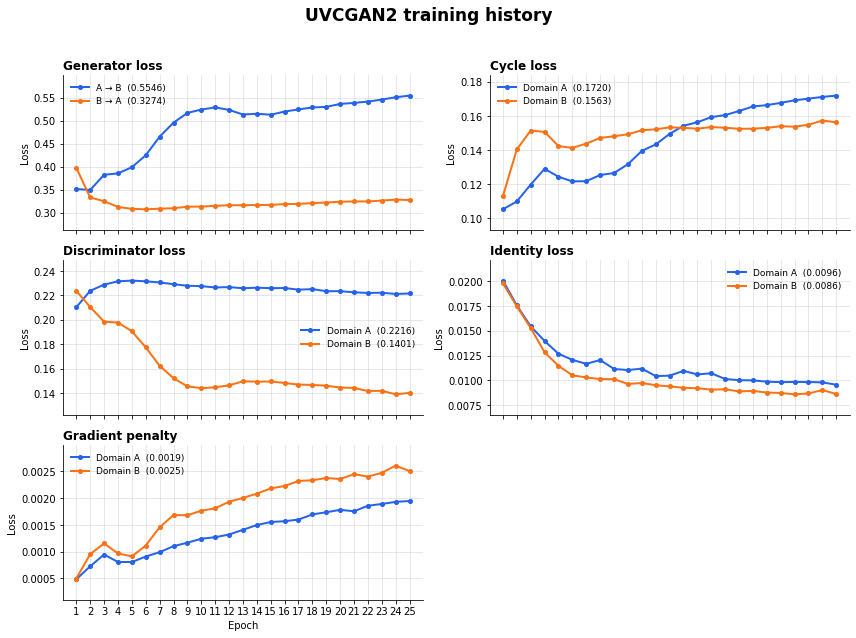

In [3]:
plotTrainTrans("/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/crystalSmall_onlySynthbert/model_m(uvcgan2)_d(basic)_g(vit-modnet)_uvcgan2-bn_(False:10.0:0.01:5e-05:bs75)/history.csv")

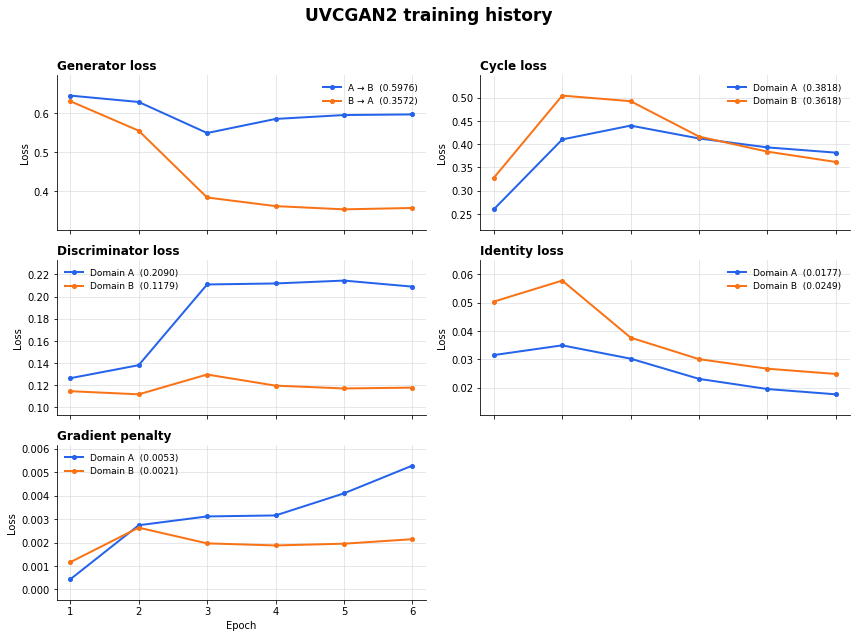

In [15]:
plotTrainTrans("/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/crystalSmall_2256_nobackgroundtraining/model_m(uvcgan2)_d(basic)_g(vit-modnet)_uvcgan2-bn_(False:10.0:0.01:5e-05:bs75)/history.csv")

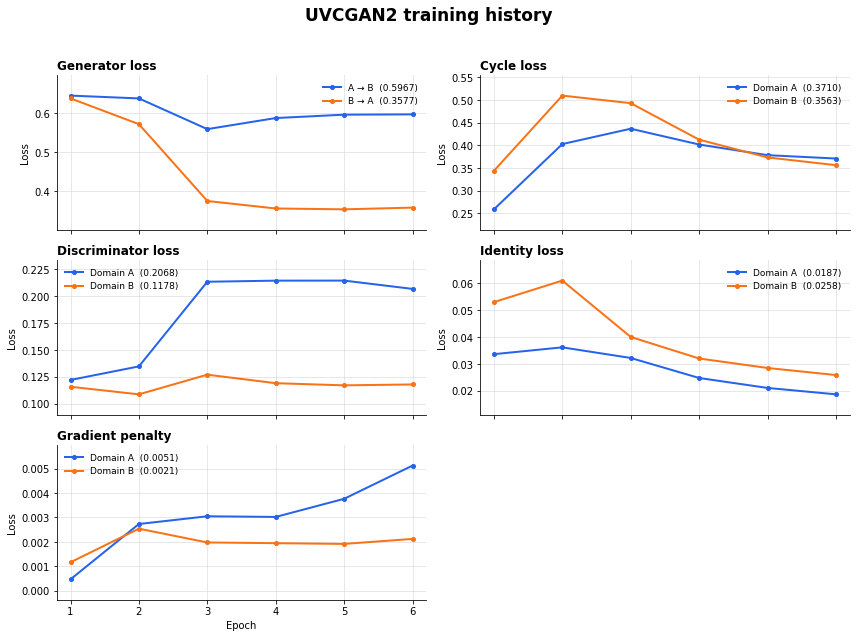

In [26]:
plotTrainTrans("/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/crystalSmall_chatFix/model_m(uvcgan2)_d(basic)_g(vit-modnet)_uvcgan2-bn_(False:10.0:0.01:5e-05:bs75)/history.csv")

In [23]:
from pathlib import Path
from PIL import Image
import random
import numpy as np
import matplotlib.pyplot as plt

def _ssim(image_a, image_b, window_size=11):
    """Compute SSIM with a local uniform window using only NumPy."""
    image_a = np.asarray(image_a.convert("RGB"), dtype=np.float32) / 255.0
    image_b = np.asarray(image_b.convert("RGB"), dtype=np.float32) / 255.0
    if image_a.shape != image_b.shape:
        raise ValueError(f"Images must have the same shape: {image_a.shape} != {image_b.shape}")

    window_size = min(window_size, *image_a.shape[:2])
    if window_size % 2 == 0:
        window_size -= 1
    if window_size < 1:
        raise ValueError("Images must not be empty")

    def local_mean(values):
        integral = np.pad(values, ((1, 0), (1, 0)), mode="constant")
        integral = integral.cumsum(axis=0).cumsum(axis=1)
        sums = (
            integral[window_size:, window_size:]
            - integral[:-window_size, window_size:]
            - integral[window_size:, :-window_size]
            + integral[:-window_size, :-window_size]
        )
        return sums / (window_size ** 2)

    c1, c2 = 0.01 ** 2, 0.03 ** 2
    channel_scores = []
    for channel in range(image_a.shape[2]):
        a, b = image_a[:, :, channel], image_b[:, :, channel]
        mean_a, mean_b = local_mean(a), local_mean(b)
        var_a = np.maximum(local_mean(a * a) - mean_a * mean_a, 0)
        var_b = np.maximum(local_mean(b * b) - mean_b * mean_b, 0)
        cov_ab = local_mean(a * b) - mean_a * mean_b
        score = (
            (2 * mean_a * mean_b + c1) * (2 * cov_ab + c2)
            / ((mean_a ** 2 + mean_b ** 2 + c1) * (var_a + var_b + c2))
        )
        channel_scores.append(float(score.mean()))
    return float(np.mean(channel_scores))

def plotBert(nazwa):
    evals_dir = Path(nazwa)
    image_types = ["masked_a", "real_a", "reco_a", "masked_b", "real_b", "reco_b"]
    titles = ["A - Masked", "A - Real", "A - Reconstruction",
            "B - Masked", "B - Real", "B - Reconstruction"]

    if not evals_dir.exists():
        print(f"Evaluation folder not found: {evals_dir.resolve()}")
    else:
        sample_ids_by_type = [
            {path.stem for path in (evals_dir / image_type).glob("sample_*") if path.is_file()}
            for image_type in image_types
        ]
        common_sample_ids = set.intersection(*sample_ids_by_type)

        if not common_sample_ids:
            print(f"No sample is present for all six image types in {evals_dir.resolve()}")
        else:
            metrics = {"a": {}, "b": {}}
            for sample_id in sorted(common_sample_ids):
                for domain in ("a", "b"):
                    with Image.open(evals_dir / f"real_{domain}" / f"{sample_id}.png") as image:
                        real_image = image.convert("RGB")
                    with Image.open(evals_dir / f"reco_{domain}" / f"{sample_id}.png") as image:
                        reco_image = image.convert("RGB")
                    real_array = np.asarray(real_image, dtype=np.float32) / 255.0
                    reco_array = np.asarray(reco_image, dtype=np.float32) / 255.0
                    contrast_ratio = float(reco_array.std() / max(real_array.std(), 1e-8))
                    metrics[domain][sample_id] = (
                        _ssim(real_image, reco_image), contrast_ratio
                    )

            print("Reconstruction metrics (higher SSIM is better; contrast ratio near 1 preserves contrast):")
            for domain in ("a", "b"):
                domain_metrics = list(metrics[domain].values())
                mean_ssim = np.mean([item[0] for item in domain_metrics])
                mean_contrast = np.mean([item[1] for item in domain_metrics])
                print(
                    f"{domain.upper()}: SSIM={mean_ssim:.3f}, "
                    f"contrast ratio={mean_contrast:.3f}, n={len(domain_metrics)}"
                )

            sample_ids = random.sample(
                list(common_sample_ids),
                k=min(5, len(common_sample_ids)),
            )

            fig, axes = plt.subplots(
                len(sample_ids), len(image_types),
                figsize=(18, 3.5 * len(sample_ids)),
                squeeze=False,
            )
            fig.suptitle("Masked input and reconstruction comparison",
                        fontsize=15, fontweight="bold")

            for row, sample_id in enumerate(sample_ids):
                for col, (image_type, title) in enumerate(zip(image_types, titles)):
                    image_path = evals_dir / image_type / f"{sample_id}.png"
                    with Image.open(image_path) as image:
                        axes[row, col].imshow(image.copy())

                    axes[row, col].set_title(title, fontsize=11, fontweight="bold")
                    axes[row, col].axis("off")

                score_a = metrics["a"][sample_id][0]
                score_b = metrics["b"][sample_id][0]
                axes[row, 0].set_ylabel(
                    f"{sample_id}\nSSIM A={score_a:.3f}, B={score_b:.3f}",
                    fontsize=9,
                )

            fig.tight_layout()
            plt.show()

Reconstruction metrics (higher SSIM is better; contrast ratio near 1 preserves contrast):
A: SSIM=0.854, contrast ratio=0.938, n=100
B: SSIM=0.968, contrast ratio=0.985, n=100


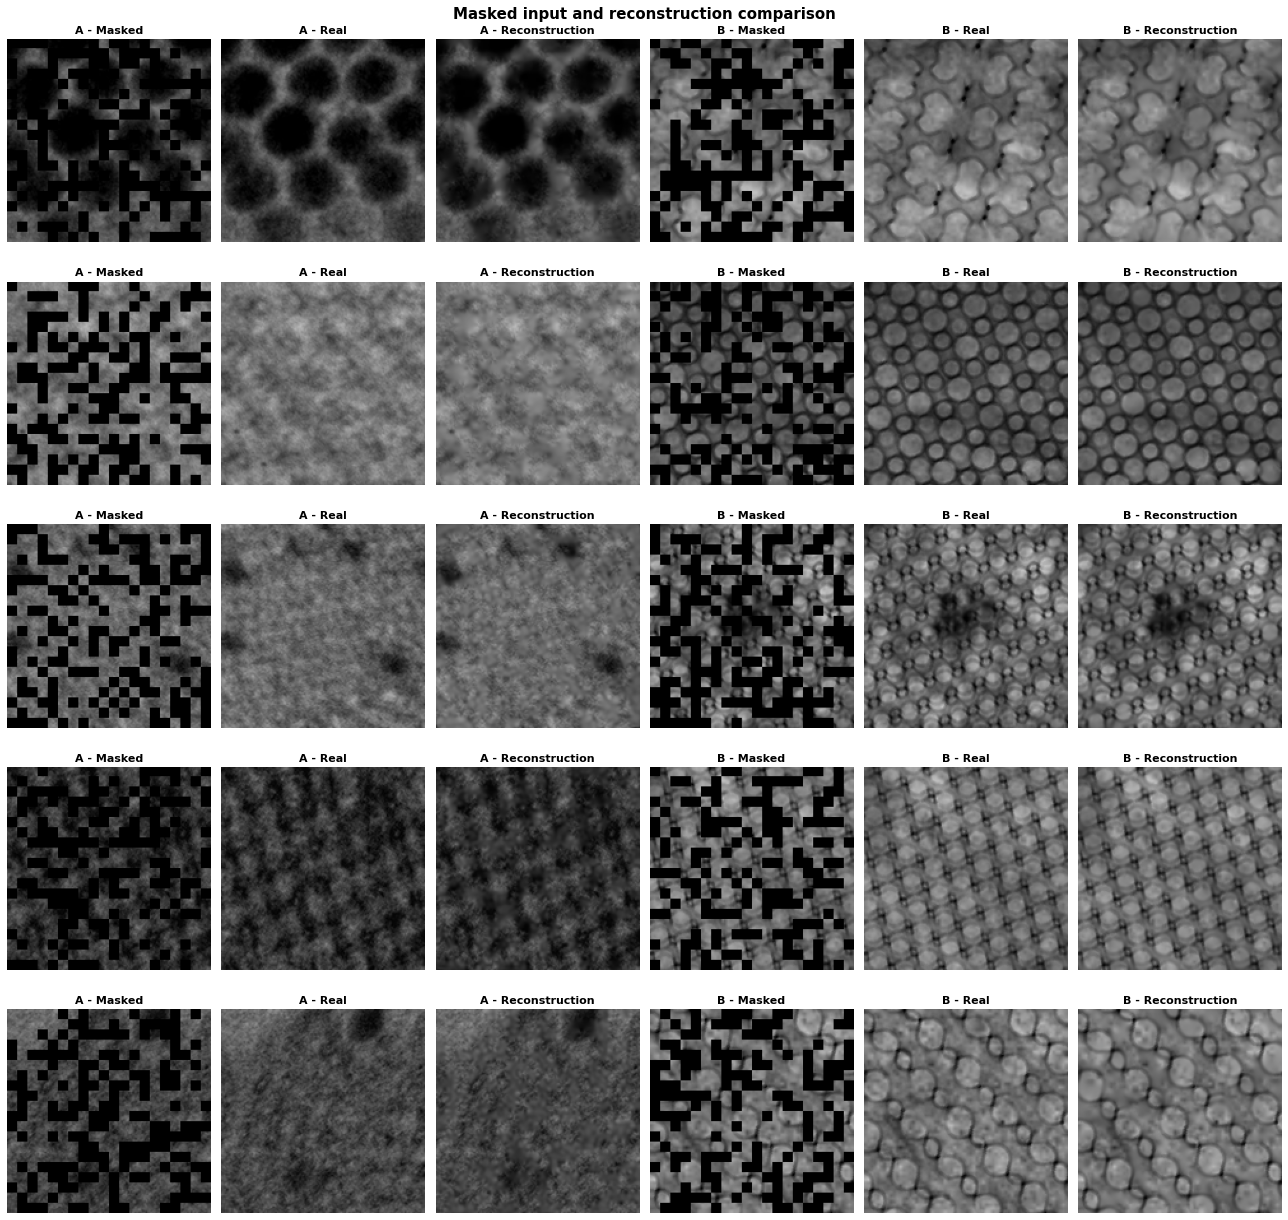

In [24]:
plotBert("/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/BertFirstonlysynththen60normal/evals/final/images_eval-val")

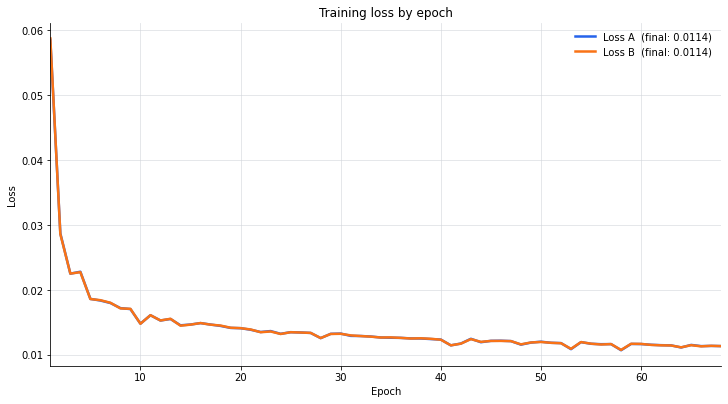

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/BertFirstonlysynththen60normal/history.csv").sort_values("epoch")
window = 1

colors = {"loss_a": "#2563eb", "loss_b": "#f97316"}

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

for column, label in [("loss_a", "Loss A"), ("loss_b", "Loss B")]:
    color = colors[column]
    ax.plot(df["epoch"], df[column], color=color, alpha=0.22, linewidth=1)
    smooth = df[column].rolling(window, min_periods=1).mean()
    ax.plot(
        df["epoch"], smooth, color=color, linewidth=2.5,
        label=f"{label}  (final: {df[column].iloc[-1]:.4f})",
    )

ax.set(
    title="Training loss by epoch",
    xlabel="Epoch",
    ylabel="Loss",
    xlim=(df["epoch"].min(), df["epoch"].max()),
)
ax.grid(True, color="#d1d5db", linewidth=0.8, alpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()